# Adaptive Ensemble for Daily Sales and Revenue Forecasting (M5, 70 store–department series)

**Authors:** Shapagat Bolatbek, Symbat Salim — Astana IT University

This notebook runs the full experiment described in Section V (Methods and Materials) of the paper and produces
every number, table and figure used in the Results, Discussion, Conclusion and Abstract. Nothing is simulated:
all results come from the real M5 Walmart data.

**Pipeline**
1. Download M5 and aggregate the 30,490 item–store series into 70 store–department series for two targets
   (unit sales and revenue = units × weekly price).
2. Rolling-origin evaluation: the last 224 days form eight 28-day windows W1–W8.
   W1–W3 = tuning, W4 = selection of the ensemble temperature τ, W5–W8 = test.
   Every model is refitted on all data before each window.
3. Seven base models: SNaive, ETS, SARIMAX, Prophet (statistical), LightGBM (ML), LSTM and CNN-LSTM (DL).
4. Adaptive ensemble (ENS) with series- and horizon-specific softmax weights computed from the RMSSE of the
   three previous windows, plus two benchmarks: equal weights (EW) and per-series selection (SEL).
5. Evaluation: MAE, RMSE, MAPE, RMSSE/WRMSSE, skill, bias, Diebold–Mariano tests, Friedman–Nemenyi test,
   ensemble-weight analysis, run times.

**How to run in Google Colab**
1. `Runtime → Change runtime type → T4 GPU` (speeds up LSTM/CNN-LSTM a lot; CPU also works, just slower).
2. `Runtime → Run all`. Allow Google Drive access when asked: all intermediate results are saved to
   `MyDrive/m5_ensemble/`, so if Colab disconnects you just press *Run all* again and finished work
   (every window, every seed, every tuning trial) is reloaded instead of recomputed.
3. If the first cell's `pip install` asks you to restart the session, restart and press *Run all* again.
4. When it finishes, download the executed notebook (`File → Download → .ipynb`) and the folder
   `MyDrive/m5_ensemble/outputs/` (it contains `latex_results.tex`, `results_tables.xlsx` and the figures).

Expected run time on Colab: roughly 2–3 hours in total (statistical models and LightGBM run on the CPU;
the deep-learning models use the GPU). Keep the browser tab open to avoid idle disconnects.

In [1]:
# Install the libraries that are not pre-installed in Colab (harmless if already installed)
import sys, subprocess
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'statsforecast', 'optuna',
                'scikit-posthocs', 'prophet', 'lightgbm'], check=False)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'statsforecast', 'optuna', 'scikit-posthocs', 'prophet', 'lightgbm'], returncode=0)

In [2]:
import os, time, json, zipfile, urllib.request, warnings, logging
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings('ignore')
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)
logging.getLogger('prophet').setLevel(logging.WARNING)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

BASE = './'
try:                                    # in Colab: keep data, cache and outputs on Google Drive
    from google.colab import drive
    drive.mount('/content/drive'); BASE = '/content/drive/MyDrive/m5_ensemble/'
except ImportError:
    pass                                # running locally: use the current folder
DATA_DIR  = BASE + 'm5_data/'
CACHE_DIR = BASE + 'cache/'
OUT_DIR   = BASE + 'outputs/'
for d in (DATA_DIR, CACHE_DIR, OUT_DIR): os.makedirs(d, exist_ok=True)
SEED = 2024
np.random.seed(SEED)

import platform, torch, lightgbm, statsforecast, prophet, optuna
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Python', platform.python_version(), '| CPU cores:', os.cpu_count(), '| device:', DEVICE)
print('numpy', np.__version__, '| pandas', pd.__version__, '| torch', torch.__version__,
      '| lightgbm', lightgbm.__version__, '| statsforecast', statsforecast.__version__,
      '| prophet', prophet.__version__, '| optuna', optuna.__version__)

Mounted at /content/drive
Python 3.13.16 | CPU cores: 2 | device: cuda
numpy 2.1.3 | pandas 2.2.3 | torch 2.11.0+cu130 | lightgbm 4.6.0 | statsforecast 2.1.1 | prophet 1.5.0 | optuna 5.0.0


## 1. Data download and preparation
The official M5 files are hosted on Kaggle (login required). To make the notebook run without credentials we
download the identical files from the public mirror maintained by Nixtla. The file `sales_train_evaluation.csv`
contains days d_1 … d_1941 (29 Jan 2011 – 22 May 2016), exactly the period used in the paper.

In [3]:
URL = 'https://github.com/Nixtla/m5-forecasts/raw/main/datasets/m5.zip'
zpath = DATA_DIR + 'm5.zip'
if not os.path.exists(zpath):
    urllib.request.urlretrieve(URL, zpath)
with zipfile.ZipFile(zpath) as z:
    for f in ['calendar.csv', 'sales_train_evaluation.csv', 'sell_prices.csv']:
        if not os.path.exists(DATA_DIR + f): z.extract(f, DATA_DIR)
print(sorted(os.listdir(DATA_DIR)))

['calendar.csv', 'm5.zip', 'sales_train_evaluation.csv', 'sell_prices.csv']


In [4]:
N_DAYS = 1941
cal = pd.read_csv(DATA_DIR + 'calendar.csv', parse_dates=['date']).iloc[:N_DAYS].reset_index(drop=True)
sales = pd.read_csv(DATA_DIR + 'sales_train_evaluation.csv')
prices = pd.read_csv(DATA_DIR + 'sell_prices.csv')
ids = sales[['item_id', 'dept_id', 'cat_id', 'store_id', 'state_id']]
Yitem = sales[[f'd_{i}' for i in range(1, N_DAYS + 1)]].to_numpy(np.float32)   # 30,490 x 1,941

# weekly price matrix (item-store x week) -> daily
weeks = cal['wm_yr_wk'].to_numpy()
wk_index = {w: i for i, w in enumerate(np.unique(weeks))}
day_wk = np.array([wk_index[w] for w in weeks])
prices = prices[prices.wm_yr_wk.isin(wk_index.keys())]
row_of = pd.Series(np.arange(len(ids)), index=ids['store_id'] + '|' + ids['item_id'])
P = np.full((len(ids), len(wk_index)), np.nan, np.float32)
P[row_of.loc[prices['store_id'] + '|' + prices['item_id']].to_numpy(),
  prices['wm_yr_wk'].map(wk_index).to_numpy()] = prices['sell_price'].to_numpy()
Pday = P[:, day_wk]
print('Units sold in weeks without a price record:', float(np.nansum(Yitem[np.isnan(Pday)])))
Ritem = np.nan_to_num(Yitem * Pday)                       # Eq. (1): revenue per item-store-day

grp = (ids['store_id'] + '_' + ids['dept_id']).to_numpy()
series = np.unique(grp)
U  = np.stack([Yitem[grp == s].sum(0) for s in series]).astype(np.float64)   # unit sales, 70 x 1941
RV = np.stack([Ritem[grp == s].sum(0) for s in series]).astype(np.float64)   # revenue (USD), 70 x 1941
# relative department price index: mean over items of price / item's average price
with np.errstate(invalid='ignore'):
    Pn = P / np.nanmean(P, 1, keepdims=True)
PI = np.stack([np.nanmean(Pn[grp == s], 0) for s in series])[:, day_wk]
del Yitem, Ritem, Pday, sales, prices

NS, ND = U.shape
store = np.array([s.rsplit('_', 2)[0] for s in series])
dept  = np.array(['_'.join(s.split('_')[2:]) for s in series])
state = np.array([s[:2] for s in series])
cat   = np.array([s.split('_')[2] for s in series])
TARGETS = {'units': U, 'revenue': RV}
print(NS, 'series x', ND, 'days')
summary = pd.DataFrame({'mean units/day': U.mean(1), 'mean revenue/day': RV.mean(1), 'cat': cat, 'state': state},
                       index=series).groupby('cat')[['mean units/day', 'mean revenue/day']].describe().round(0)
summary

Units sold in weeks without a price record: 0.0
70 series x 1941 days


mean units/day                                                    mean revenue/day                                                      
                   count   mean    std    min    25%    50%     75%     max            count    mean     std    min    25%     50%     75%     max
cat                                                                                                                                               
FOODS               30.0  789.0  726.0  179.0  281.0  402.0  1268.0  2913.0             30.0  1909.0  1512.0  445.0  679.0  1314.0  2863.0  6410.0
HOBBIES             20.0  161.0  151.0   12.0   28.0  106.0   287.0   464.0             20.0   601.0   600.0   27.0   62.0   393.0  1094.0  1692.0
HOUSEHOLD           20.0  380.0  277.0  100.0  127.0  288.0   587.0  1126.0             20.0  1471.0   917.0  466.0  609.0  1378.0  2102.0  4047.0

### Rolling-origin windows and Christmas handling
Window W_k starts at day index `ORIGINS[k-1]` (0-based). Stores are closed on 25 December; these days are
replaced for the statistical models by the mean of the same weekday in the adjacent weeks, and they are excluded
from all error calculations (the closure is known in advance and is not a forecasting problem).

In [5]:
H = 28
ORIGINS = [1717 + H * k for k in range(8)]
for k, o in enumerate(ORIGINS):
    print(f'W{k+1}: {cal.date[o].date()} – {cal.date[o+H-1].date()}  (train days: {o})')
XMAS = np.where((cal.date.dt.month == 12) & (cal.date.dt.day == 25))[0]
print('Christmas indices:', XMAS)
EVAL_MASK = np.ones(ND, bool); EVAL_MASK[XMAS] = False

def fix_xmas(Yt, T):
    """Replace Christmas closures in the training part (days < T) by the mean of t-7 and t+7."""
    Z = Yt.copy()
    for t in XMAS:
        if t < T:
            nb = [Z[:, t - 7]] + ([Yt[:, t + 7]] if t + 7 < T else [])
            Z[:, t] = np.mean(nb, 0)
    return Z

W1: 2015-10-12 – 2015-11-08  (train days: 1717)
W2: 2015-11-09 – 2015-12-06  (train days: 1745)
W3: 2015-12-07 – 2016-01-03  (train days: 1773)
W4: 2016-01-04 – 2016-01-31  (train days: 1801)
W5: 2016-02-01 – 2016-02-28  (train days: 1829)
W6: 2016-02-29 – 2016-03-27  (train days: 1857)
W7: 2016-03-28 – 2016-04-24  (train days: 1885)
W8: 2016-04-25 – 2016-05-22  (train days: 1913)
Christmas indices: [ 330  696 1061 1426 1791]


### Evaluation functions (Section V-E)

In [6]:
def scale_sq(Yt, T):
    """In-sample mean squared one-step naive error (RMSSE denominator), per series."""
    return np.mean(np.diff(Yt[:, :T], axis=1) ** 2, 1)

def rev_weights(T):
    """WRMSSE weights: share of revenue in the last 28 training days."""
    r = RV[:, T - 28:T].sum(1); return r / r.sum()

def rmsse(Yt, T, F, hs=slice(0, H)):
    """RMSSE per series for forecast F (NS x H) made at origin T, restricted to horizons hs."""
    y = Yt[:, T:T + H][:, hs]; f = F[:, hs]; m = EVAL_MASK[T:T + H][hs]
    return np.sqrt(np.mean((y[:, m] - f[:, m]) ** 2, 1) / scale_sq(Yt, T))

def wrmsse(Yt, T, F):
    return float(np.sum(rev_weights(T) * rmsse(Yt, T, F)))

BUCKETS = [slice(0, 7), slice(7, 14), slice(14, 28)]

### Caching helper
Each base model produces an array of forecasts with shape (8 windows, 70 series, 28 days) per target, together
with the wall-clock time of each refit.

In [7]:
def rolling(name, target, fit_predict):
    """Run fit_predict(Yt, T) -> (NS x H) at each origin. Each window is cached separately, so an interrupted
    run resumes where it stopped; cached windows are reported exactly like freshly computed ones."""
    Yt = TARGETS[target]; F = np.zeros((8, NS, H)); times = []
    for k in range(8):
        fpath = f'{CACHE_DIR}F_{name}_{target}_W{k+1}.npy'; tpath = fpath.replace('.npy', '.json')
        if os.path.exists(fpath):
            F[k] = np.load(fpath); secs = json.load(open(tpath))['secs']; tag = 'cached'
        else:
            SEED_SECS.clear(); t0 = time.time(); F[k] = np.maximum(fit_predict(Yt, ORIGINS[k]), 0)
            secs = sum(SEED_SECS) if SEED_SECS else time.time() - t0   # DL: sum of the per-seed training times
            np.save(fpath, F[k]); json.dump({'secs': secs}, open(tpath, 'w')); tag = 'computed'
        times.append(secs)
        print(f'  {name:8s} {target:7s} W{k+1}: WRMSSE={wrmsse(Yt, ORIGINS[k], F[k]):.4f}  (refit {secs:.1f}s, {tag})', flush=True)
    return F, times

FC, TIMES = {}, {}
SEED_SECS = []

## 2. Statistical models
### 2.1 Seasonal naive (SNaive) and ETS (automatic AICc selection, weekly seasonality, `statsforecast`)

In [8]:
from statsforecast import StatsForecast
from statsforecast.models import AutoETS, AutoARIMA, ARIMA

def snaive(Yt, T):
    Z = fix_xmas(Yt, T); last = Z[:, T - 7:T]
    return np.tile(last, (1, 4))

def long_df(Z, T, start=0):
    return pd.DataFrame({'unique_id': np.repeat(np.arange(NS), T - start),
                         'ds': np.tile(cal.date.values[start:T], NS), 'y': Z[:, start:T].ravel()})

def ets(Yt, T):
    Z = fix_xmas(Yt, T)
    sf = StatsForecast(models=[AutoETS(season_length=7)], freq='D', n_jobs=1)
    f = sf.forecast(df=long_df(Z, T), h=H)
    return f.sort_values(['unique_id', 'ds'])['AutoETS'].to_numpy().reshape(NS, H)

for tg in TARGETS:
    for nm, fn in [('SNaive', snaive), ('ETS', ets)]:
        FC[nm, tg], TIMES[nm, tg] = rolling(nm, tg, fn)

  SNaive   units   W1: WRMSSE=0.9736  (refit 0.0s, cached)
  SNaive   units   W2: WRMSSE=1.0792  (refit 0.0s, cached)
  SNaive   units   W3: WRMSSE=1.0599  (refit 0.0s, cached)
  SNaive   units   W4: WRMSSE=1.1566  (refit 0.0s, cached)
  SNaive   units   W5: WRMSSE=1.0376  (refit 0.0s, cached)
  SNaive   units   W6: WRMSSE=0.9762  (refit 0.0s, cached)
  SNaive   units   W7: WRMSSE=1.0290  (refit 0.0s, cached)
  SNaive   units   W8: WRMSSE=0.8919  (refit 0.0s, cached)
  ETS      units   W1: WRMSSE=0.8070  (refit 99.9s, cached)
  ETS      units   W2: WRMSSE=1.0075  (refit 100.7s, cached)
  ETS      units   W3: WRMSSE=0.9844  (refit 102.1s, cached)
  ETS      units   W4: WRMSSE=0.8104  (refit 104.8s, cached)
  ETS      units   W5: WRMSSE=0.8227  (refit 112.0s, cached)
  ETS      units   W6: WRMSSE=0.8556  (refit 111.8s, cached)
  ETS      units   W7: WRMSSE=0.8825  (refit 110.9s, cached)
  ETS      units   W8: WRMSSE=0.7924  (refit 111.7s, cached)
  SNaive   revenue W1: WRMSSE=1.0148  (re

### 2.2 SARIMAX
Regressors: event indicator, the state's SNAP flag, the department price index and K Fourier pairs for annual
seasonality. To keep the run time feasible (one automatic ARIMA search with regressors takes ≈10–30 s per series),
the ARIMA orders are selected **once per series and target** at the first origin (W1) by the stepwise AICc search
(`AutoARIMA`, weekly period m = 7, Fourier K = 4), and K ∈ {2,…,6} is then chosen by AICc with these orders.
At every origin the coefficients are re-estimated on the most recent 730 days.

In [9]:
tt = np.arange(ND)
ev_any = cal.event_type_1.notna().astype(float).to_numpy()
snap = np.stack([cal[f'snap_{s}'].to_numpy() for s in state]).astype(float)
SAR_HIST = 730

def sar_X(i, K):
    cols = {'ev': ev_any, 'snap': snap[i], 'pi': PI[i]}
    for k in range(1, K + 1):
        cols[f's{k}'] = np.sin(2 * np.pi * k * tt / 365.25); cols[f'c{k}'] = np.cos(2 * np.pi * k * tt / 365.25)
    return pd.DataFrame(cols)

def sar_frames(Z, i, T, K):
    S = T - SAR_HIST; x = sar_X(i, K)
    tr = pd.concat([pd.DataFrame({'unique_id': i, 'ds': cal.date.values[S:T], 'y': Z[i, S:T]}),
                    x.iloc[S:T].reset_index(drop=True)], axis=1)
    fu = pd.concat([pd.DataFrame({'unique_id': i, 'ds': cal.date.values[T:T + H]}),
                    x.iloc[T:T + H].reset_index(drop=True)], axis=1)
    return tr, fu

def sar_select(target):
    """Order + K selection at the first origin; cached per series so it can resume."""
    Yt = TARGETS[target]; T = ORIGINS[0]; Z = fix_xmas(Yt, T); spec = []; t0 = time.time()
    for i in range(NS):
        path = f'{CACHE_DIR}sarimax_spec_{target}_{i}.json'
        if not os.path.exists(path):
            tr, _ = sar_frames(Z, i, T, 4)
            sf = StatsForecast(models=[AutoARIMA(season_length=7)], freq='D', n_jobs=1); sf.fit(df=tr)
            p, q, P_, Q, s, d, D = sf.fitted_[0, 0].model_['arma']
            best = (np.inf, 4)
            for K in range(2, 7):
                tr, _ = sar_frames(Z, i, T, K)
                try:
                    sf = StatsForecast(models=[ARIMA(order=(p, d, q), seasonal_order=(P_, D, Q), season_length=7)], freq='D')
                    sf.fit(df=tr); a = sf.fitted_[0, 0].model_['aicc']
                    if a < best[0]: best = (a, K)
                except Exception:
                    pass
            json.dump(dict(order=[int(p), int(d), int(q)], seasonal=[int(P_), int(D), int(Q)], K=int(best[1])), open(path, 'w'))
        spec.append(json.load(open(path)))
    print(f'SARIMAX order selection ({target}) done ({time.time()-t0:.0f}s in this session)')
    return spec

def make_sarimax(spec):
    def fp(Yt, T):
        Z = fix_xmas(Yt, T); out = np.zeros((NS, H))
        for i in range(NS):
            tr, fu = sar_frames(Z, i, T, spec[i]['K'])
            try:
                sf = StatsForecast(models=[ARIMA(order=tuple(spec[i]['order']), seasonal_order=tuple(spec[i]['seasonal']),
                                                 season_length=7)], freq='D')
                out[i] = sf.forecast(df=tr, h=H, X_df=fu)['ARIMA'].to_numpy()
            except Exception as e:      # fall back to the seasonal naive forecast if estimation fails
                print('   SARIMAX fallback', i, e); out[i] = np.tile(Z[i, T - 7:T], 4)
        return out
    return fp

SAR_SPEC = {}
for tg in TARGETS:
    SAR_SPEC[tg] = sar_select(tg)
    FC['SARIMAX', tg], TIMES['SARIMAX', tg] = rolling('SARIMAX', tg, make_sarimax(SAR_SPEC[tg]))
for tg in TARGETS:
    sp_ = pd.DataFrame(SAR_SPEC[tg])
    print(tg, '| most common orders:', sp_.apply(lambda r: f"{tuple(r.order)}{tuple(r.seasonal)}", axis=1).value_counts().head(3).to_dict(),
          '| K counts:', sp_.K.value_counts().sort_index().to_dict())

SARIMAX order selection (units) done (18s in this session)
  SARIMAX  units   W1: WRMSSE=0.7128  (refit 41.5s, cached)
  SARIMAX  units   W2: WRMSSE=0.9623  (refit 42.3s, cached)
  SARIMAX  units   W3: WRMSSE=0.9821  (refit 40.7s, cached)
  SARIMAX  units   W4: WRMSSE=0.9847  (refit 39.7s, cached)
  SARIMAX  units   W5: WRMSSE=0.9598  (refit 41.8s, cached)
  SARIMAX  units   W6: WRMSSE=0.8920  (refit 39.8s, cached)
  SARIMAX  units   W7: WRMSSE=0.9472  (refit 40.4s, cached)
  SARIMAX  units   W8: WRMSSE=0.8409  (refit 41.0s, cached)
SARIMAX order selection (revenue) done (18s in this session)
  SARIMAX  revenue W1: WRMSSE=0.6942  (refit 45.4s, cached)
  SARIMAX  revenue W2: WRMSSE=0.9945  (refit 42.6s, cached)
  SARIMAX  revenue W3: WRMSSE=1.0322  (refit 44.4s, cached)
  SARIMAX  revenue W4: WRMSSE=1.0045  (refit 41.5s, cached)
  SARIMAX  revenue W5: WRMSSE=0.9545  (refit 41.8s, cached)
  SARIMAX  revenue W6: WRMSSE=0.9299  (refit 40.6s, cached)
  SARIMAX  revenue W7: WRMSSE=0.9259  (r

### 2.3 Prophet
Weekly and yearly seasonality, M5 calendar events as holidays. The changepoint prior scale is tuned on W1–W3
(grid {0.01, 0.05, 0.1, 0.5}, criterion: mean WRMSSE), separately per target.

In [10]:
from prophet import Prophet
HOL = pd.concat([cal[['date', c]].rename(columns={'date': 'ds', c: 'holiday'}) for c in ['event_name_1', 'event_name_2']]).dropna()

def make_prophet(cps):
    def fp(Yt, T):
        Z = fix_xmas(Yt, T); out = np.zeros((NS, H)); fut = pd.DataFrame({'ds': cal.date[T:T + H].values})
        for i in range(NS):
            m = Prophet(weekly_seasonality=True, yearly_seasonality=True, daily_seasonality=False,
                        holidays=HOL, changepoint_prior_scale=cps)
            m.fit(pd.DataFrame({'ds': cal.date[:T].values, 'y': Z[i, :T]}))
            out[i] = m.predict(fut)['yhat'].to_numpy()
        return out
    return fp

PROPHET_CPS = {}
for tg in TARGETS:
    scores = {}
    for cps in [0.01, 0.05, 0.1, 0.5]:
        path = f'{CACHE_DIR}prophet_tune_{tg}_{cps}.json'
        if not os.path.exists(path):
            fp = make_prophet(cps)
            json.dump({'score': float(np.mean([wrmsse(TARGETS[tg], ORIGINS[k], np.maximum(fp(TARGETS[tg], ORIGINS[k]), 0))
                                               for k in range(3)]))}, open(path, 'w'))
        scores[cps] = json.load(open(path))['score']
        print(f'  Prophet {tg} cps={cps}: tuning WRMSSE (W1-W3) = {scores[cps]:.4f}', flush=True)
    PROPHET_CPS[tg] = {'best': min(scores, key=scores.get), 'scores': scores}
    print(tg, 'selected changepoint_prior_scale =', PROPHET_CPS[tg]['best'])
    FC['Prophet', tg], TIMES['Prophet', tg] = rolling('Prophet', tg, make_prophet(PROPHET_CPS[tg]['best']))

  Prophet units cps=0.01: tuning WRMSSE (W1-W3) = 0.8243
  Prophet units cps=0.05: tuning WRMSSE (W1-W3) = 0.7992
  Prophet units cps=0.1: tuning WRMSSE (W1-W3) = 0.7982
  Prophet units cps=0.5: tuning WRMSSE (W1-W3) = 0.7782
units selected changepoint_prior_scale = 0.5
  Prophet  units   W1: WRMSSE=0.6914  (refit 74.6s, cached)
  Prophet  units   W2: WRMSSE=0.8188  (refit 74.3s, cached)
  Prophet  units   W3: WRMSSE=0.8245  (refit 77.1s, cached)
  Prophet  units   W4: WRMSSE=0.7822  (refit 79.3s, cached)
  Prophet  units   W5: WRMSSE=0.9146  (refit 78.6s, cached)
  Prophet  units   W6: WRMSSE=0.8647  (refit 78.6s, cached)
  Prophet  units   W7: WRMSSE=0.7742  (refit 83.9s, cached)
  Prophet  units   W8: WRMSSE=0.8124  (refit 85.7s, cached)
  Prophet revenue cps=0.01: tuning WRMSSE (W1-W3) = 0.8789
  Prophet revenue cps=0.05: tuning WRMSSE (W1-W3) = 0.8535
  Prophet revenue cps=0.1: tuning WRMSSE (W1-W3) = 0.8505
  Prophet revenue cps=0.5: tuning WRMSSE (W1-W3) = 0.8385
revenue selecte

## 3. Machine learning: global LightGBM
One model for all 70 series (per target) with Tweedie loss. Features (Section V-B): target lags 28–56 (weekly
steps) and 364; rolling mean and standard deviation of the 28-day lag over 7, 28 and 56 days; calendar variables;
event indicators; SNAP flag; department price index, its weekly change and its ratio to the 52-week mean; store,
state, department and category identifiers. Because the shortest lag is 28 days, all 28 forecasts are produced
directly. Hyperparameters are tuned with Optuna (TPE, 25 trials per target) minimising the mean WRMSSE over W1–W3.

In [11]:
import lightgbm as lgb

def lagged(A, k):
    B = np.full_like(A, np.nan); B[:, k:] = A[:, :-k]; return B

def roll(A, w, fn):
    return getattr(pd.DataFrame(A.T).rolling(w), fn)().to_numpy().T

def codes(a): return pd.factorize(a, sort=True)[0]
ev_code = pd.Categorical(cal.event_type_1.fillna('none'),
                         categories=['none', 'Cultural', 'National', 'Religious', 'Sporting']).codes

def build_features(Yt):
    F = {}
    for k in [28, 35, 42, 49, 56, 364]: F[f'lag{k}'] = lagged(Yt, k)
    L28 = lagged(Yt, 28)
    for w in [7, 28, 56]:
        F[f'rmean{w}'] = roll(L28, w, 'mean'); F[f'rstd{w}'] = roll(L28, w, 'std')
    dt = cal.date
    for nm, v in [('dow', dt.dt.dayofweek), ('month', dt.dt.month), ('mday', dt.dt.day),
                  ('woy', dt.dt.isocalendar().week.astype(int)), ('year', dt.dt.year)]:
        F[nm] = np.tile(v.to_numpy(float), (NS, 1))
    F['ev_any'] = np.tile(ev_any, (NS, 1)); F['ev_type'] = np.tile(ev_code.astype(float), (NS, 1))
    F['snap'] = snap; F['pi'] = PI; F['pi_chg'] = PI / lagged(PI, 7) - 1; F['pi_ratio'] = PI / roll(PI, 364, 'mean')
    for nm, a in [('store', store), ('state', state), ('dept', dept), ('cat', cat)]:
        F[nm] = np.tile(codes(a)[:, None].astype(float), (1, ND))
    return F

CATS = ['store', 'state', 'dept', 'cat', 'ev_type']
FEATS = {tg: build_features(Yt) for tg, Yt in TARGETS.items()}
def frame(F, days): return pd.DataFrame({k: v[:, days].ravel() for k, v in F.items()})
FIRST_ROW = 400     # first training day with all features available (lag 364 + rolling windows)

def make_lgb(params, n_rounds, target):
    F = FEATS[target]
    def fp(Yt, T):
        tr = np.arange(FIRST_ROW, T)
        ds = lgb.Dataset(frame(F, tr), Yt[:, tr].ravel(), categorical_feature=CATS)
        m = lgb.train({**params, 'objective': 'tweedie', 'verbose': -1, 'seed': SEED,
                       'num_threads': os.cpu_count(), 'deterministic': True, 'force_row_wise': True}, ds, n_rounds)
        return m.predict(frame(F, np.arange(T, T + H))).reshape(NS, H)
    return fp

LGB_BEST = {}
optuna.logging.set_verbosity(optuna.logging.WARNING)
for tg in TARGETS:
    path = f'{CACHE_DIR}lgb_params_{tg}.json'
    if not os.path.exists(path):
        def objective(trial):
            p = dict(num_leaves=trial.suggest_int('num_leaves', 31, 255, log=True),
                     learning_rate=trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
                     feature_fraction=trial.suggest_float('feature_fraction', 0.5, 1.0),
                     tweedie_variance_power=trial.suggest_float('tweedie_variance_power', 1.05, 1.5),
                     min_data_in_leaf=trial.suggest_int('min_data_in_leaf', 20, 200, log=True))
            n = trial.suggest_int('n_rounds', 200, 1200, step=100)
            fp = make_lgb(p, n, tg)
            return np.mean([wrmsse(TARGETS[tg], ORIGINS[k], np.maximum(fp(TARGETS[tg], ORIGINS[k]), 0)) for k in range(3)])
        t0 = time.time()
        study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED),
                                    study_name=f'lgb_{tg}', storage=f'sqlite:///{CACHE_DIR}optuna.db', load_if_exists=True)
        done = len([t for t in study.trials if t.state.name == 'COMPLETE'])
        study.optimize(objective, n_trials=max(0, 25 - done))
        secs = sum((t.datetime_complete - t.datetime_start).total_seconds() for t in study.trials if t.state.name == 'COMPLETE')
        json.dump({'params': study.best_params, 'value': study.best_value, 'secs': secs, 'n_trials': len(study.trials)}, open(path, 'w'))
    LGB_BEST[tg] = json.load(open(path))
    print(tg, 'LightGBM best tuning WRMSSE = %.4f' % LGB_BEST[tg]['value'], LGB_BEST[tg]['params'])
    p = dict(LGB_BEST[tg]['params']); n = p.pop('n_rounds')
    FC['LightGBM', tg], TIMES['LightGBM', tg] = rolling('LightGBM', tg, make_lgb(p, n, tg))

units LightGBM best tuning WRMSSE = 0.6452 {'num_leaves': 119, 'learning_rate': 0.017485079117097038, 'feature_fraction': 0.6457367402206172, 'tweedie_variance_power': 1.1050235653055456, 'min_data_in_leaf': 34, 'n_rounds': 900}
  LightGBM units   W1: WRMSSE=0.5925  (refit 14.4s, cached)
  LightGBM units   W2: WRMSSE=0.6530  (refit 14.9s, cached)
  LightGBM units   W3: WRMSSE=0.6900  (refit 14.9s, cached)
  LightGBM units   W4: WRMSSE=0.6810  (refit 15.4s, cached)
  LightGBM units   W5: WRMSSE=0.7059  (refit 15.4s, cached)
  LightGBM units   W6: WRMSSE=0.7093  (refit 15.8s, cached)
  LightGBM units   W7: WRMSSE=0.6060  (refit 15.9s, cached)
  LightGBM units   W8: WRMSSE=0.6385  (refit 16.0s, cached)
revenue LightGBM best tuning WRMSSE = 0.6749 {'num_leaves': 189, 'learning_rate': 0.021022664855392902, 'feature_fraction': 0.6072571073119869, 'tweedie_variance_power': 1.0800467873490416, 'min_data_in_leaf': 23, 'n_rounds': 500}
  LightGBM revenue W1: WRMSSE=0.6065  (refit 9.8s, cached)
 

## 4. Deep learning: global LSTM and CNN-LSTM (PyTorch)
Inputs: the last L days of the scaled target (series divided by its training mean) plus day-of-week (sin/cos),
event, SNAP and price-index channels; store and department embeddings; and the known calendar/price covariates of
the 28 forecast days. A dense head outputs all 28 forecasts at once (multi-output, no recursion).
Training samples are taken at every 7th origin; the last four origins (whose targets cover the final 49 training
days) form the early-stopping validation set (Adam, MSE loss, ≤20 epochs, patience 3).
Hyperparameters are tuned with Optuna (10 trials per model and target) on W3 with one seed; final forecasts are
averaged over three seeds.

In [12]:
import torch, torch.nn as nn
torch.set_num_threads(os.cpu_count())
dow = cal.date.dt.dayofweek.to_numpy()
EXOG = np.stack([np.tile(np.sin(2 * np.pi * dow / 7), (NS, 1)), np.tile(np.cos(2 * np.pi * dow / 7), (NS, 1)),
                 np.tile(ev_any, (NS, 1)), snap, PI], 1)                       # NS x 5 x ND
ST_CODE, DP_CODE = codes(store), codes(dept)

def dl_tensors(Yt, T, L, stride=7, start=FIRST_ROW):
    scale = Yt[:, :T].mean(1, keepdims=True); Z = Yt / scale
    def make(origins):
        xp, xf, y = [], [], []
        for o in origins:
            xp.append(np.concatenate([Z[:, None, o - L:o], EXOG[:, :, o - L:o]], 1))
            xf.append(EXOG[:, :, o:o + H].reshape(NS, -1))
            y.append(Z[:, o:o + H] if o + H <= T else np.zeros((NS, H)))
        t = lambda a: torch.tensor(np.concatenate(a), dtype=torch.float32, device=DEVICE)
        n = len(origins)
        return (t(xp).transpose(1, 2).contiguous(), t(xf), t(y),
                torch.tensor(np.tile(ST_CODE, n), device=DEVICE), torch.tensor(np.tile(DP_CODE, n), device=DEVICE))
    last = T - H
    val_o = [last - 7 * j for j in range(4)][::-1]
    tr_o = list(range(last - 28, max(start, L) - 1, -stride))[::-1]
    return make(tr_o), make(val_o), make([T]), scale

class Net(nn.Module):
    def __init__(s, units=64, layers=1, dropout=0.1, conv=0, filters=32, kernel=5, nin=6, nfut=5 * H):
        super().__init__()
        s.conv = None
        if conv:
            mods = []
            for i in range(conv):
                mods += [nn.Conv1d(nin if i == 0 else filters, filters, kernel, padding=kernel // 2), nn.ReLU()]
            s.conv = nn.Sequential(*mods)
        s.lstm = nn.LSTM(filters if conv else nin, units, layers, batch_first=True, dropout=dropout if layers > 1 else 0)
        s.es, s.ed, s.drop = nn.Embedding(10, 4), nn.Embedding(7, 4), nn.Dropout(dropout)
        s.head = nn.Sequential(nn.Linear(units + 8 + nfut, 128), nn.ReLU(), nn.Linear(128, H))
    def forward(s, xp, xf, st, dp):
        if s.conv is not None: xp = s.conv(xp.transpose(1, 2)).transpose(1, 2)
        h, _ = s.lstm(xp)
        return s.head(torch.cat([s.drop(h[:, -1]), s.es(st), s.ed(dp), xf], 1))

def train_dl(Yt, T, hp, seed, max_epochs=20, patience=3):
    torch.manual_seed(seed); np.random.seed(seed)
    tr, va, te, scale = dl_tensors(Yt, T, hp['L'])
    net = Net(hp['units'], hp['layers'], hp['dropout'], hp.get('conv', 0), hp.get('filters', 32), hp.get('kernel', 5)).to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=hp['lr']); lossf = nn.MSELoss()
    best, bad, n = np.inf, 0, len(tr[0]); g = torch.Generator().manual_seed(seed); state = None
    for ep in range(max_epochs):
        net.train(); perm = torch.randperm(n, generator=g).to(DEVICE)
        for b in range(0, n, 256):
            idx = perm[b:b + 256]; opt.zero_grad()
            loss = lossf(net(tr[0][idx], tr[1][idx], tr[3][idx], tr[4][idx]), tr[2][idx]); loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
        net.eval()
        with torch.no_grad(): vl = lossf(net(va[0], va[1], va[3], va[4]), va[2]).item()
        if vl < best - 1e-5: best, bad, state = vl, 0, {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    net.load_state_dict(state); net.eval()
    with torch.no_grad(): p = net(te[0], te[1], te[3], te[4]).cpu().numpy()
    return p * scale

def make_dl(hp, name, target, seeds=(0, 1, 2)):
    """Average of three seeds; each seed is cached so an interrupted window resumes at the next seed."""
    def fp(Yt, T):
        out = []
        for s in seeds:
            path = f'{CACHE_DIR}seed_{name}_{target}_{T}_{s}.npy'
            if not os.path.exists(path):
                t0 = time.time(); np.save(path, train_dl(Yt, T, hp, s))
                json.dump({'secs': time.time() - t0}, open(path.replace('.npy', '.json'), 'w'))
            out.append(np.load(path)); SEED_SECS.append(json.load(open(path.replace('.npy', '.json')))['secs'])
        return np.mean(out, 0)
    return fp

DL_BEST = {}
for nm, conv in [('LSTM', False), ('CNN-LSTM', True)]:
    for tg in TARGETS:
        path = f'{CACHE_DIR}dl_params_{nm}_{tg}.json'
        if not os.path.exists(path):
            def objective(trial):
                hp = dict(L=trial.suggest_categorical('L', [56, 112, 224]),
                          layers=trial.suggest_int('layers', 1, 2),
                          units=trial.suggest_categorical('units', [32, 64, 128]),
                          dropout=trial.suggest_float('dropout', 0.0, 0.3),
                          lr=trial.suggest_float('lr', 1e-4, 1e-2, log=True))
                if conv:
                    hp.update(conv=trial.suggest_int('conv', 1, 2), filters=trial.suggest_categorical('filters', [16, 32, 64]),
                              kernel=trial.suggest_categorical('kernel', [3, 5, 7]))
                Yt = TARGETS[tg]; T = ORIGINS[2]
                return wrmsse(Yt, T, np.maximum(train_dl(Yt, T, hp, seed=0), 0))
            t0 = time.time()
            study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED),
                                        study_name=f'dl_{nm}_{tg}', storage=f'sqlite:///{CACHE_DIR}optuna.db', load_if_exists=True)
            done = len([t for t in study.trials if t.state.name == 'COMPLETE'])
            study.optimize(objective, n_trials=max(0, 10 - done))
            secs = sum((t.datetime_complete - t.datetime_start).total_seconds() for t in study.trials if t.state.name == 'COMPLETE')
            json.dump({'params': study.best_params, 'value': study.best_value, 'secs': secs}, open(path, 'w'))
        DL_BEST[nm, tg] = json.load(open(path))
        print(nm, tg, 'best W3 WRMSSE = %.4f' % DL_BEST[nm, tg]['value'], DL_BEST[nm, tg]['params'], flush=True)
        FC[nm, tg], TIMES[nm, tg] = rolling(nm, tg, make_dl(DL_BEST[nm, tg]['params'], nm, tg))

LSTM units best W3 WRMSSE = 0.8031 {'L': 112, 'layers': 2, 'units': 128, 'dropout': 0.2209700703927824, 'lr': 0.0009982634551351653}
  LSTM     units   W1: WRMSSE=0.7666  (refit 59.2s, cached)
  LSTM     units   W2: WRMSSE=0.8278  (refit 62.5s, cached)
  LSTM     units   W3: WRMSSE=0.7854  (refit 78.4s, cached)
  LSTM     units   W4: WRMSSE=0.7361  (refit 78.9s, cached)
  LSTM     units   W5: WRMSSE=0.8827  (refit 69.3s, cached)
  LSTM     units   W6: WRMSSE=0.7952  (refit 53.8s, cached)
  LSTM     units   W7: WRMSSE=0.7008  (refit 57.9s, cached)
  LSTM     units   W8: WRMSSE=0.7598  (refit 45.7s, cached)
LSTM revenue best W3 WRMSSE = 0.8624 {'L': 112, 'layers': 2, 'units': 32, 'dropout': 0.2202436195038405, 'lr': 0.0003778425903036013}
  LSTM     revenue W1: WRMSSE=0.7478  (refit 11.0s, cached)
  LSTM     revenue W2: WRMSSE=0.8827  (refit 11.5s, cached)
  LSTM     revenue W3: WRMSSE=0.8757  (refit 11.7s, cached)
  LSTM     revenue W4: WRMSSE=0.8152  (refit 11.8s, cached)
  LSTM     re

## 5. Adaptive ensemble (Eqs. 2–3) and combination benchmarks
For window W_k the weight of model m for series i and horizon bucket b ∈ {1–7, 8–14, 15–28} is a softmax of
−ē/τ, where ē is the model's mean RMSSE in that bucket over the three previous windows. Models whose ē exceeds
SNaive's are not admissible. τ is chosen on W4 from {0.01, 0.05, 0.1, 0.25, 0.5, 1, ∞}.
EW = equal-weight mean of all seven models; SEL = model with the lowest ē per series and bucket.

In [13]:
MODELS = ['SNaive', 'ETS', 'SARIMAX', 'Prophet', 'LightGBM', 'LSTM', 'CNN-LSTM']
FAMILY = {'SNaive': 'Statistical', 'ETS': 'Statistical', 'SARIMAX': 'Statistical', 'Prophet': 'Statistical',
          'LightGBM': 'ML', 'LSTM': 'DL', 'CNN-LSTM': 'DL'}
TAUS = [0.01, 0.05, 0.1, 0.25, 0.5, 1.0, np.inf]
TEST = [4, 5, 6, 7]        # W5..W8 (0-based)

def bucket_errors(tg):
    """RMSSE per model, window, series and horizon bucket: shape (M, 8, NS, 3)."""
    Yt = TARGETS[tg]
    return np.array([[np.stack([rmsse(Yt, ORIGINS[k], FC[m, tg][k], b) for b in BUCKETS], 1)
                      for k in range(8)] for m in MODELS])

def combine(tg, tau, k, E):
    """Ensemble weights (M, NS, 3) and forecasts (NS, H) for window k."""
    ebar = E[:, k - 3:k].mean(1)                               # M x NS x 3
    adm = ebar <= ebar[MODELS.index('SNaive')][None]
    if np.isinf(tau): w = adm.astype(float)
    else:
        z = -(ebar - ebar.min(0, keepdims=True)) / tau        # shift for numerical stability
        w = np.where(adm, np.exp(z), 0.0)
    w = w / w.sum(0, keepdims=True)
    Fk = np.stack([FC[m, tg][k] for m in MODELS])             # M x NS x H
    out = np.zeros((NS, H))
    for j, b in enumerate(BUCKETS): out[:, b] = np.einsum('mn,mnh->nh', w[:, :, j], Fk[:, :, b])
    return w, out

def select(tg, k, E):
    ebar = E[:, k - 3:k].mean(1); best = ebar.argmin(0)        # NS x 3
    Fk = np.stack([FC[m, tg][k] for m in MODELS]); out = np.zeros((NS, H))
    for j, b in enumerate(BUCKETS): out[:, b] = np.take_along_axis(Fk[:, :, b], best[None, :, j, None], 0)[0]
    return best, out

ERR, TAU_SEL, W_ENS, SEL_CHOICE = {}, {}, {}, {}
for tg in TARGETS:
    E = ERR[tg] = bucket_errors(tg); Yt = TARGETS[tg]
    tau_scores = {t: wrmsse(Yt, ORIGINS[3], combine(tg, t, 3, E)[1]) for t in TAUS}
    TAU_SEL[tg] = min(tau_scores, key=tau_scores.get)
    print(tg, 'W4 WRMSSE by tau:', {str(k): round(v, 4) for k, v in tau_scores.items()}, '-> tau =', TAU_SEL[tg])
    FC['ENS', tg] = np.zeros((8, NS, H)); FC['EW', tg] = np.zeros((8, NS, H)); FC['SEL', tg] = np.zeros((8, NS, H))
    W_ENS[tg] = {}; SEL_CHOICE[tg] = {}
    for k in range(3, 8):
        W_ENS[tg][k], FC['ENS', tg][k] = combine(tg, TAU_SEL[tg], k, E)
        SEL_CHOICE[tg][k], FC['SEL', tg][k] = select(tg, k, E)
        FC['EW', tg][k] = np.mean([FC[m, tg][k] for m in MODELS], 0)
ALL = MODELS + ['EW', 'SEL', 'ENS']

units W4 WRMSSE by tau: {'0.01': 0.7131, '0.05': 0.6926, '0.1': 0.6907, '0.25': 0.7023, '0.5': 0.7123, '1.0': 0.7196, 'inf': 0.7305} -> tau = 0.1
revenue W4 WRMSSE by tau: {'0.01': 0.7446, '0.05': 0.7229, '0.1': 0.7175, '0.25': 0.7299, '0.5': 0.7425, '1.0': 0.7525, 'inf': 0.7683} -> tau = 0.1


## 6. Test accuracy over W5–W8 (RQ1)

In [14]:
def test_arrays(tg, m):
    """Actuals and forecasts over the 112 test days: (NS, 112)."""
    y = np.concatenate([TARGETS[tg][:, ORIGINS[k]:ORIGINS[k] + H] for k in TEST], 1)
    f = np.concatenate([FC[m, tg][k] for k in TEST], 1)
    return y, f

def metrics(tg, m):
    Yt = TARGETS[tg]; y, f = test_arrays(tg, m); e = f - y
    w_rmsse = [wrmsse(Yt, ORIGINS[k], FC[m, tg][k]) for k in TEST]
    return dict(WRMSSE=np.mean(w_rmsse), MAE=np.mean(np.abs(e).mean(1)), RMSE=np.mean(np.sqrt((e ** 2).mean(1))),
                MAPE=100 * np.mean((np.abs(e) / y).mean(1)), Bias=100 * np.mean(e.sum(1) / y.sum(1)))

def refit_minutes(tg, m):
    if m in MODELS: return np.mean(TIMES[m, tg]) / 60
    return sum(np.mean(TIMES[b, tg]) for b in MODELS) / 60

print('Zero actual values in the test period:', {tg: int((test_arrays(tg, 'SNaive')[0] == 0).sum()) for tg in TARGETS})
RES = {}
for tg in TARGETS:
    df = pd.DataFrame({m: metrics(tg, m) for m in ALL}).T
    df.insert(1, 'Skill', 100 * (1 - df.WRMSSE / df.loc['SNaive', 'WRMSSE']))
    df['Time_min'] = [refit_minutes(tg, m) for m in ALL]
    RES[tg] = df
    print(f'\n=== {tg} ==='); display(df.round(3))

for tg in TARGETS:
    r = RES[tg]; best_single = r.loc[MODELS, 'WRMSSE'].idxmin()
    print(f'{tg}: best single = {best_single}; ENS vs best single {100*(1-r.loc["ENS","WRMSSE"]/r.loc[best_single,"WRMSSE"]):.2f}% | '
          f'vs EW {100*(1-r.loc["ENS","WRMSSE"]/r.loc["EW","WRMSSE"]):.2f}% | vs SEL {100*(1-r.loc["ENS","WRMSSE"]/r.loc["SEL","WRMSSE"]):.2f}%')

Zero actual values in the test period: {'units': 0, 'revenue': 0}

=== units ===


,WRMSSE,Skill,MAE,RMSE,MAPE,Bias,Time_min
SNaive,0.984,0.000,90.527,117.382,20.258,-5.474,0.000
ETS,0.838,14.775,76.922,99.729,17.418,-3.418,1.779
SARIMAX,0.910,7.490,84.331,107.404,20.211,-0.754,0.682
Prophet,0.841,14.453,78.957,100.602,17.426,-1.398,1.317
LightGBM,0.665,32.401,60.930,79.151,15.091,-1.498,0.256
LSTM,0.785,20.233,71.552,92.366,16.142,-4.299,1.053
CNN-LSTM,0.805,18.208,72.843,94.236,16.217,-4.650,0.241
EW,0.738,24.977,67.439,87.722,15.786,-3.070,5.328
SEL,0.696,29.228,63.297,82.572,15.734,-1.986,5.328
ENS,0.669,31.982,61.366,79.987,15.247,-2.433,5.328



=== revenue ===


,WRMSSE,Skill,MAE,RMSE,MAPE,Bias,Time_min
SNaive,1.070,0.000,285.195,368.683,19.848,-5.601,0.000
ETS,0.917,14.305,243.402,315.614,16.517,-4.282,1.709
SARIMAX,0.944,11.846,254.901,325.715,18.620,-2.181,0.714
Prophet,0.902,15.704,241.559,308.364,16.615,-2.280,1.279
LightGBM,0.709,33.744,187.485,245.507,14.432,-2.327,0.172
LSTM,0.840,21.564,222.887,289.788,15.405,-4.905,0.199
CNN-LSTM,0.834,22.093,221.740,288.380,15.421,-4.538,0.220
EW,0.791,26.139,208.006,272.469,14.979,-3.731,4.294
SEL,0.747,30.229,196.169,258.558,15.101,-2.656,4.294
ENS,0.712,33.436,188.023,246.890,14.537,-2.983,4.294


units: best single = LightGBM; ENS vs best single -0.62% | vs EW 9.34% | vs SEL 3.89%
revenue: best single = LightGBM; ENS vs best single -0.47% | vs EW 9.88% | vs SEL 4.60%



=== units: WRMSSE per window ===


,W1,W2,W3,W4,W5,W6,W7,W8
SNaive,0.974,1.079,1.060,1.157,1.038,0.976,1.029,0.892
ETS,0.807,1.007,0.984,0.810,0.823,0.856,0.883,0.792
SARIMAX,0.713,0.962,0.982,0.985,0.960,0.892,0.947,0.841
Prophet,0.691,0.819,0.824,0.782,0.915,0.865,0.774,0.812
LightGBM,0.592,0.653,0.690,0.681,0.706,0.709,0.606,0.638
LSTM,0.767,0.828,0.785,0.736,0.883,0.795,0.701,0.760
CNN-LSTM,0.763,0.815,0.791,0.821,0.889,0.810,0.730,0.789
EW,NaN,NaN,NaN,0.729,0.766,0.758,0.709,0.719
SEL,NaN,NaN,NaN,0.733,0.739,0.719,0.658,0.670
ENS,NaN,NaN,NaN,0.691,0.709,0.697,0.622,0.648


best method per test window: {'W5': 'LightGBM', 'W6': 'ENS', 'W7': 'LightGBM', 'W8': 'LightGBM'}

=== revenue: WRMSSE per window ===


,W1,W2,W3,W4,W5,W6,W7,W8
SNaive,1.015,1.148,1.179,1.257,1.131,1.063,1.106,0.981
ETS,0.853,1.100,1.043,0.836,0.904,0.946,0.955,0.865
SARIMAX,0.694,0.994,1.032,1.004,0.955,0.930,0.926,0.964
Prophet,0.750,0.886,0.879,0.835,0.918,0.913,0.864,0.914
LightGBM,0.607,0.684,0.735,0.698,0.720,0.797,0.643,0.677
LSTM,0.748,0.883,0.876,0.815,0.953,0.861,0.733,0.811
CNN-LSTM,0.710,0.845,0.840,0.780,0.951,0.870,0.720,0.795
EW,NaN,NaN,NaN,0.763,0.818,0.823,0.750,0.771
SEL,NaN,NaN,NaN,0.749,0.763,0.814,0.690,0.720
ENS,NaN,NaN,NaN,0.718,0.738,0.765,0.650,0.697


best method per test window: {'W5': 'LightGBM', 'W6': 'ENS', 'W7': 'LightGBM', 'W8': 'LightGBM'}


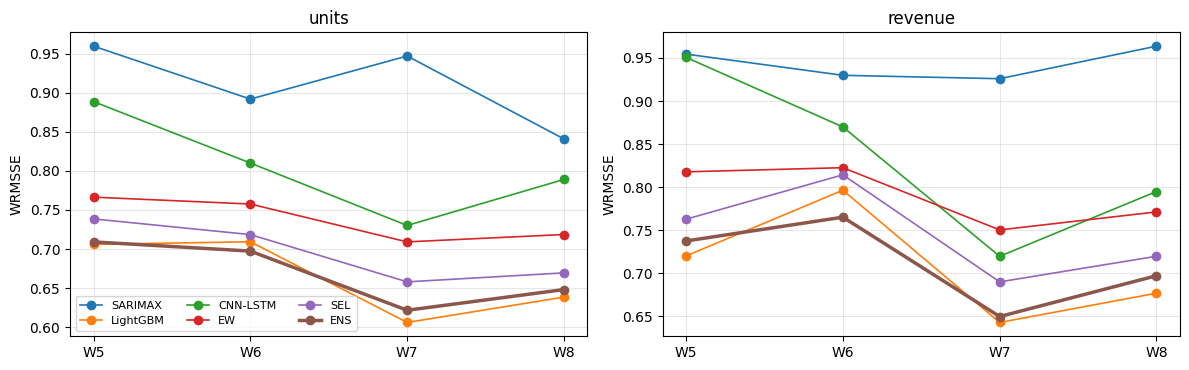

In [15]:
# WRMSSE in every window (W1-W3 tuning, W4 tau selection, W5-W8 test)
PERWIN = {}
for tg in TARGETS:
    PERWIN[tg] = pd.DataFrame({m: [wrmsse(TARGETS[tg], ORIGINS[k], FC[m, tg][k]) if (m in MODELS or k >= 3) else np.nan
                                   for k in range(8)] for m in ALL}, index=[f'W{k+1}' for k in range(8)]).T
    print(f'\n=== {tg}: WRMSSE per window ==='); display(PERWIN[tg].round(3))
    tw = PERWIN[tg][[f'W{k+1}' for k in TEST]]
    print('best method per test window:', tw.idxmin().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, tg in zip(axes, TARGETS):
    for m in ['SARIMAX', 'LightGBM', 'CNN-LSTM', 'EW', 'SEL', 'ENS']:
        ax.plot(range(5, 9), PERWIN[tg].loc[m, [f'W{k+1}' for k in TEST]], marker='o', label=m, lw=2.5 if m == 'ENS' else 1.2)
    ax.set_xticks(range(5, 9), [f'W{k}' for k in range(5, 9)]); ax.set_title(tg); ax.set_ylabel('WRMSSE'); ax.grid(alpha=.3)
axes[0].legend(ncol=3, fontsize=8); plt.tight_layout(); plt.savefig(OUT_DIR + 'wrmsse_windows.png', dpi=150); plt.show()

### Diebold–Mariano tests (squared loss, per series, 112 test days)
HAC variance with autocovariances up to lag 6 (one week) and the Harvey–Leybourne–Newbold small-sample
correction; two-sided test at α = 0.05 against a Student t distribution with n − 1 degrees of freedom.

In [16]:
def dm_test(e1, e2, h=7):
    d = e1 ** 2 - e2 ** 2; n = len(d); dbar = d.mean(); dc = d - dbar
    gam = [np.sum(dc[k:] * dc[:n - k]) / n for k in range(h)]
    var = (gam[0] + 2 * sum(gam[1:])) / n
    if var <= 0:   # fall back to Bartlett weights if the truncated estimate is not positive
        var = (gam[0] + 2 * sum((1 - k / h) * gam[k] for k in range(1, h))) / n
    stat = dbar / np.sqrt(var) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return stat, 2 * stats.t.sf(abs(stat), n - 1)

DM = {}
for tg in TARGETS:
    y, fe = test_arrays(tg, 'ENS'); rows = {}
    for m in ALL[:-1]:
        _, fo = test_arrays(tg, m); B = N = W = 0
        for i in range(NS):
            s, p = dm_test(fe[i] - y[i], fo[i] - y[i])
            if p < 0.05 and s < 0: B += 1
            elif p < 0.05 and s > 0: W += 1
            else: N += 1
        rows[m] = dict(B=B, N=N, W=W)
    DM[tg] = pd.DataFrame(rows).T
pd.concat(DM, axis=1)

units        revenue       
             B   N  W       B   N  W
SNaive      63   7  0      65   5  0
ETS         29  40  1      28  41  1
SARIMAX     47  23  0      43  27  0
Prophet     33  37  0      32  37  1
LightGBM     1  66  3       4  62  4
LSTM        26  41  3      28  42  0
CNN-LSTM    36  33  1      23  47  0
EW          19  48  3      20  49  1
SEL         11  57  2      16  52  2

### Friedman test and Nemenyi post-hoc comparison (per-series RMSSE averaged over the four test windows)

units: Friedman chi2(9) = 288.9, p = 5.98e-57; Nemenyi CD = 1.62
  average ranks: {'ENS': 2.9, 'LightGBM': 3.07, 'EW': 3.9, 'SEL': 4.33, 'LSTM': 5.61, 'ETS': 5.86, 'CNN-LSTM': 5.9, 'Prophet': 6.31, 'SARIMAX': 7.67, 'SNaive': 9.44}
  Nemenyi p (ENS vs others): {'SNaive': 0.0, 'ETS': 0.0, 'SARIMAX': 0.0, 'Prophet': 0.0, 'LightGBM': 1.0, 'LSTM': 0.0, 'CNN-LSTM': 0.0, 'EW': 0.6316, 'SEL': 0.1392}
revenue: Friedman chi2(9) = 289.2, p = 5.12e-57; Nemenyi CD = 1.62
  average ranks: {'ENS': 2.86, 'LightGBM': 3.08, 'EW': 3.77, 'SEL': 4.61, 'Prophet': 5.86, 'CNN-LSTM': 5.87, 'ETS': 5.94, 'LSTM': 5.99, 'SARIMAX': 7.43, 'SNaive': 9.6}
  Nemenyi p (ENS vs others): {'SNaive': 0.0, 'ETS': 0.0, 'SARIMAX': 0.0, 'Prophet': 0.0, 'LightGBM': 1.0, 'LSTM': 0.0, 'CNN-LSTM': 0.0, 'EW': 0.744, 'SEL': 0.0221}


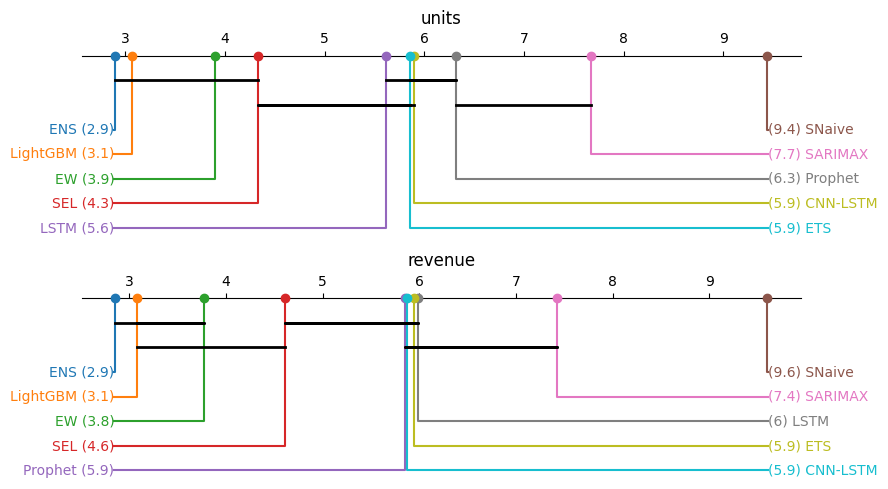

In [17]:
import scikit_posthocs as sp
FRIED, RANKS, NEMENYI = {}, {}, {}
Q05 = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164}  # Demsar (2006)
for tg in TARGETS:
    Yt = TARGETS[tg]
    R = pd.DataFrame({m: np.mean([rmsse(Yt, ORIGINS[k], FC[m, tg][k]) for k in TEST], 0) for m in ALL})
    FRIED[tg] = stats.friedmanchisquare(*[R[m] for m in ALL])
    RANKS[tg] = R.rank(axis=1).mean().sort_values()
    NEMENYI[tg] = sp.posthoc_nemenyi_friedman(R.values); NEMENYI[tg].index = NEMENYI[tg].columns = ALL
    k_ = len(ALL); CD = Q05[k_] * np.sqrt(k_ * (k_ + 1) / (6 * NS))
    print(f'{tg}: Friedman chi2({k_-1}) = {FRIED[tg].statistic:.1f}, p = {FRIED[tg].pvalue:.2e}; Nemenyi CD = {CD:.2f}')
    print('  average ranks:', RANKS[tg].round(2).to_dict())
    print('  Nemenyi p (ENS vs others):', NEMENYI[tg]['ENS'].drop('ENS').round(4).to_dict())

fig, axes = plt.subplots(2, 1, figsize=(9, 5))
for ax, tg in zip(axes, TARGETS):
    sp.critical_difference_diagram(RANKS[tg], NEMENYI[tg], ax=ax); ax.set_title(tg)
plt.tight_layout(); plt.savefig(OUT_DIR + 'cd_diagram.png', dpi=150); plt.show()

### Success criteria for H1 (Section V-E)

In [18]:
for tg in TARGETS:
    r = RES[tg]; best_single = r.loc[MODELS, 'WRMSSE'].idxmin()
    a = all(r.loc['ENS', 'WRMSSE'] < r.loc[m, 'WRMSSE'] for m in ALL if m != 'ENS')
    tw = PERWIN[tg][[f'W{k+1}' for k in TEST]]; wins = int((tw.idxmin() == 'ENS').sum())
    b = wins >= 3
    c_better, c_worse = DM[tg].loc[best_single, 'B'], DM[tg].loc[best_single, 'W']
    c = (c_better > NS / 2) and (c_worse <= 0.1 * NS)
    pos_skill = bool((r.loc[['LightGBM', 'LSTM', 'CNN-LSTM'], 'Skill'] > 0).all())
    print(f'{tg}: (a) lowest WRMSSE overall: {a} | (b) best in {wins}/4 windows: {b} | '
          f'(c) DM vs {best_single}: better {c_better}, worse {c_worse} -> {c} | ML/DL positive skill: {pos_skill}')

units: (a) lowest WRMSSE overall: False | (b) best in 1/4 windows: False | (c) DM vs LightGBM: better 1, worse 3 -> False | ML/DL positive skill: True
revenue: (a) lowest WRMSSE overall: False | (b) best in 1/4 windows: False | (c) DM vs LightGBM: better 4, worse 4 -> False | ML/DL positive skill: True


## 7. Differences across targets, categories and states (RQ2)

In [19]:
def group_wrmsse(tg, m, mask):
    Yt = TARGETS[tg]; vals = []
    for k in TEST:
        w = rev_weights(ORIGINS[k])[mask]; vals.append(np.sum(w * rmsse(Yt, ORIGINS[k], FC[m, tg][k])[mask]) / w.sum())
    return np.mean(vals)

GROUP = {}
for gname, labels in [('cat', cat), ('state', state)]:
    rows = {}
    for g in np.unique(labels):
        for tg in TARGETS:
            rows[(g, tg)] = {m: group_wrmsse(tg, m, labels == g) for m in ALL}
    GROUP[gname] = pd.DataFrame(rows).T
    display(GROUP[gname].round(3))
    best = GROUP[gname][MODELS].idxmin(axis=1)
    gain = 100 * (1 - GROUP[gname]['ENS'] / GROUP[gname][MODELS].min(axis=1))
    print(pd.DataFrame({'best single': best, 'ENS gain vs best single (%)': gain.round(2),
                        'ENS gain vs LightGBM (%)': (100 * (1 - GROUP[gname]['ENS'] / GROUP[gname]['LightGBM'])).round(2)}))

rel = pd.DataFrame({tg: RES[tg]['WRMSSE'] for tg in TARGETS})
rel['revenue/units - 1 (%)'] = 100 * (rel['revenue'] / rel['units'] - 1)
rel['gap to LightGBM, units (%)'] = 100 * (rel['units'] / rel.loc['LightGBM', 'units'] - 1)
rel['gap to LightGBM, revenue (%)'] = 100 * (rel['revenue'] / rel.loc['LightGBM', 'revenue'] - 1)
rel.round(3)

SNaive    ETS  SARIMAX  Prophet  LightGBM   LSTM  CNN-LSTM     EW    SEL    ENS
FOODS     units     1.064  0.926    0.860    0.930     0.669  0.813     0.854  0.787  0.698  0.681
          revenue   1.152  1.020    0.925    0.995     0.697  0.873     0.854  0.836  0.736  0.710
HOBBIES   units     0.863  0.667    1.232    0.713     0.668  0.686     0.690  0.682  0.673  0.652
          revenue   1.032  0.773    1.172    0.828     0.783  0.812     0.835  0.768  0.800  0.756
HOUSEHOLD units     0.885  0.747    0.865    0.731     0.657  0.776     0.761  0.670  0.704  0.654
          revenue   0.934  0.786    0.879    0.759     0.700  0.790     0.798  0.715  0.744  0.698

                  best single  ENS gain vs best single (%)  ENS gain vs LightGBM (%)
FOODS     units      LightGBM                        -1.84                     -1.84
          revenue    LightGBM                        -1.89                     -1.89
HOBBIES   units           ETS                         2.38                      2.52
          revenue         ETS                         2.18                      3.39
HOUSEHOLD units      LightGBM                         0.36                      0.36
          revenue    LightGBM                         0.27                      0.27


SNaive    ETS  SARIMAX  Prophet  LightGBM   LSTM  CNN-LSTM     EW    SEL    ENS
CA units     0.836  0.693    0.882    0.749     0.654  0.704     0.731  0.654  0.678  0.643
   revenue   0.883  0.741    0.873    0.808     0.680  0.757     0.744  0.682  0.723  0.674
TX units     0.897  0.774    0.817    0.708     0.625  0.684     0.678  0.652  0.673  0.624
   revenue   1.029  0.865    0.872    0.769     0.700  0.763     0.788  0.734  0.733  0.701
WI units     1.293  1.122    1.043    1.112     0.722  1.007     1.040  0.950  0.749  0.754
   revenue   1.397  1.237    1.120    1.177     0.764  1.042     1.017  1.012  0.799  0.784

           best single  ENS gain vs best single (%)  ENS gain vs LightGBM (%)
CA units      LightGBM                         1.73                      1.73
   revenue    LightGBM                         0.88                      0.88
TX units      LightGBM                         0.06                      0.06
   revenue    LightGBM                        -0.11                     -0.11
WI units      LightGBM                        -4.47                     -4.47
   revenue    LightGBM                        -2.71                     -2.71


,units,revenue,revenue/units - 1 (%),"gap to LightGBM, units (%)","gap to LightGBM, revenue (%)"
SNaive,0.984,1.070,8.811,47.932,50.930
ETS,0.838,0.917,9.411,26.076,29.340
SARIMAX,0.910,0.944,3.687,36.852,33.051
Prophet,0.841,0.902,7.219,26.552,27.228
LightGBM,0.665,0.709,6.649,0.000,0.000
LSTM,0.785,0.840,6.996,18.000,18.384
CNN-LSTM,0.805,0.834,3.643,20.996,17.586
EW,0.738,0.791,7.124,10.983,11.478
SEL,0.696,0.747,7.272,4.694,5.306
ENS,0.669,0.712,6.484,0.621,0.466


## 8. Ensemble weights (RQ3)

units mean weight per model: {'SNaive': 0.033, 'ETS': 0.146, 'SARIMAX': 0.057, 'Prophet': 0.16, 'LightGBM': 0.321, 'LSTM': 0.152, 'CNN-LSTM': 0.132}
   share of series-bucket combinations where model is admissible: {'SNaive': np.float64(1.0), 'ETS': np.float64(0.945), 'SARIMAX': np.float64(0.681), 'Prophet': np.float64(0.893), 'LightGBM': np.float64(0.951), 'LSTM': np.float64(0.932), 'CNN-LSTM': np.float64(0.931)}
   SEL choice frequency: {'SNaive': 0.004, 'ETS': 0.169, 'SARIMAX': 0.029, 'Prophet': 0.161, 'LightGBM': 0.449, 'LSTM': 0.12, 'CNN-LSTM': 0.069}
revenue mean weight per model: {'SNaive': 0.033, 'ETS': 0.135, 'SARIMAX': 0.071, 'Prophet': 0.168, 'LightGBM': 0.325, 'LSTM': 0.13, 'CNN-LSTM': 0.138}
   share of series-bucket combinations where model is admissible: {'SNaive': np.float64(1.0), 'ETS': np.float64(0.952), 'SARIMAX': np.float64(0.767), 'Prophet': np.float64(0.921), 'LightGBM': np.float64(0.965), 'LSTM': np.float64(0.939), 'CNN-LSTM': np.float64(0.942)}
   SEL choice fre

,Statistical,ML,DL
All units,0.396,0.321,0.284
All revenue,0.407,0.325,0.268
Foods,0.315,0.389,0.296
Hobbies,0.460,0.228,0.311
Household,0.453,0.309,0.237
Days 1-7,0.420,0.276,0.305
Days 8-14,0.380,0.352,0.268
Days 15-28,0.388,0.334,0.279
W5,0.372,0.345,0.283
W6,0.384,0.338,0.278


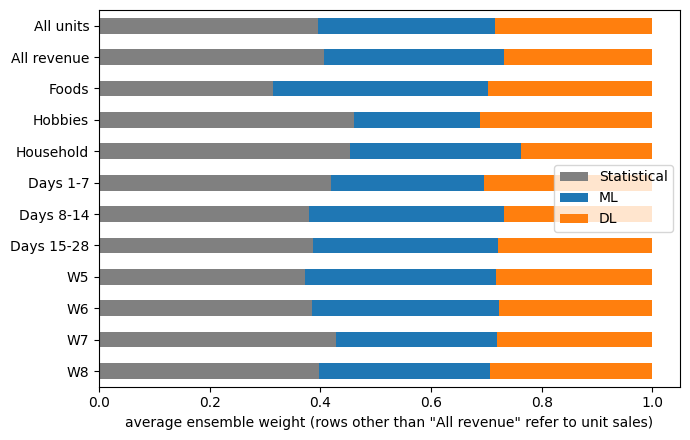

In [20]:
def fam_weights(tg, ks=TEST, series_mask=None, buckets=(0, 1, 2)):
    out = {m: [] for m in MODELS}
    for k in ks:
        w = W_ENS[tg][k]                                            # M x NS x 3
        if series_mask is not None: w = w[:, series_mask]
        for j, m in enumerate(MODELS): out[m].append(w[j][:, list(buckets)].mean())
    mw = pd.Series({m: np.mean(v) for m, v in out.items()})
    return mw, mw.groupby(FAMILY).sum()

WROWS = {}
for tg in TARGETS:
    mw, fw = fam_weights(tg); WROWS[f'All {tg}'] = fw
    print(tg, 'mean weight per model:', mw.round(3).to_dict())
    adm = np.mean([(W_ENS[tg][k] > 0) for k in TEST], 0).mean(axis=(1, 2))
    print('   share of series-bucket combinations where model is admissible:', dict(zip(MODELS, adm.round(3))))
    sel = np.concatenate([SEL_CHOICE[tg][k].ravel() for k in TEST])
    print('   SEL choice frequency:', {MODELS[j]: round(float(np.mean(sel == j)), 3) for j in range(len(MODELS))})
for c in np.unique(cat): WROWS[c.title()] = fam_weights('units', series_mask=cat == c)[1]
for j, lab in enumerate(['Days 1-7', 'Days 8-14', 'Days 15-28']): WROWS[lab] = fam_weights('units', buckets=(j,))[1]
for k in TEST: WROWS[f'W{k+1}'] = fam_weights('units', ks=[k])[1]
WFAM = pd.DataFrame(WROWS).T[['Statistical', 'ML', 'DL']]
display(WFAM.round(3))
WFAM.loc[::-1].plot.barh(stacked=True, figsize=(7, 4.5), color=['grey', 'tab:blue', 'tab:orange'])
plt.xlabel('average ensemble weight (rows other than "All revenue" refer to unit sales)'); plt.tight_layout()
plt.savefig(OUT_DIR + 'weights.png', dpi=150); plt.show()

In [21]:
# Accuracy on event days vs. other days in the test period (12 event days)
test_days = np.concatenate([np.arange(ORIGINS[k], ORIGINS[k] + H) for k in TEST])
is_ev = ev_any[test_days] == 1
print('event days in test period:', int(is_ev.sum()), list(cal.event_name_1[test_days[is_ev]]))
EVENT = {}
for tg in TARGETS:
    rows = {}
    w = np.mean([rev_weights(ORIGINS[k]) for k in TEST], 0)
    sc = np.concatenate([np.repeat(scale_sq(TARGETS[tg], ORIGINS[k])[:, None], H, 1) for k in TEST], 1)
    for m in ALL:
        y, f = test_arrays(tg, m); se = (f - y) ** 2 / sc
        r_ev, r_no = np.sqrt(se[:, is_ev].mean(1)), np.sqrt(se[:, ~is_ev].mean(1))
        rows[m] = dict(event=np.sum(w * r_ev), non_event=np.sum(w * r_no))
    EVENT[tg] = pd.DataFrame(rows).T; EVENT[tg]['ratio'] = EVENT[tg].event / EVENT[tg].non_event
pd.concat(EVENT, axis=1).round(3)

event days in test period: 12 ['SuperBowl', 'LentStart', 'ValentinesDay', 'PresidentsDay', 'LentWeek2', 'StPatricksDay', 'Purim End', 'Easter', 'Pesach End', 'OrthodoxEaster', 'Cinco De Mayo', "Mother's day"]


units                  revenue                 
          event non_event  ratio   event non_event  ratio
SNaive    1.170     0.982  1.192   1.286     1.060  1.213
ETS       0.908     0.848  1.070   1.015     0.923  1.100
SARIMAX   1.048     0.920  1.139   1.105     0.947  1.167
Prophet   0.867     0.853  1.017   0.923     0.913  1.010
LightGBM  0.749     0.668  1.120   0.811     0.711  1.141
LSTM      0.970     0.780  1.244   1.066     0.829  1.286
CNN-LSTM  0.971     0.798  1.216   1.086     0.821  1.322
EW        0.843     0.739  1.141   0.927     0.788  1.176
SEL       0.796     0.698  1.141   0.861     0.749  1.148
ENS       0.773     0.672  1.151   0.846     0.711  1.189

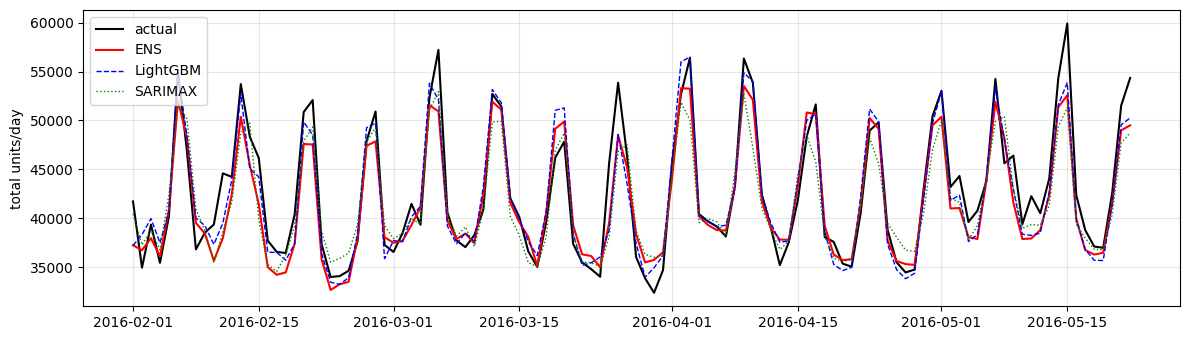

In [22]:
# Aggregate (all 70 series) actual vs. forecast for unit sales in the test period
y, fe = test_arrays('units', 'ENS'); _, fl = test_arrays('units', 'LightGBM'); _, fs = test_arrays('units', 'SARIMAX')
plt.figure(figsize=(12, 3.5))
plt.plot(cal.date[test_days], y.sum(0), 'k', label='actual'); plt.plot(cal.date[test_days], fe.sum(0), 'r', label='ENS')
plt.plot(cal.date[test_days], fl.sum(0), 'b--', lw=1, label='LightGBM'); plt.plot(cal.date[test_days], fs.sum(0), 'g:', lw=1, label='SARIMAX')
plt.legend(); plt.ylabel('total units/day'); plt.grid(alpha=.3); plt.tight_layout(); plt.savefig(OUT_DIR + 'total_units.png', dpi=150); plt.show()

In [23]:
# Tuning summary and run times
print('Selected tau:', TAU_SEL)
print('Prophet changepoint prior scale:', {tg: PROPHET_CPS[tg]['best'] for tg in TARGETS})
for tg in TARGETS:
    print('LightGBM', tg, LGB_BEST[tg]['params'], '| tuning time %.1f min' % (LGB_BEST[tg]['secs'] / 60))
for key, v in DL_BEST.items():
    print(key, v['params'], '| tuning time %.1f min' % (v['secs'] / 60))
pd.DataFrame({tg: {m: refit_minutes(tg, m) for m in MODELS} for tg in TARGETS}).round(2)

Selected tau: {'units': 0.1, 'revenue': 0.1}
Prophet changepoint prior scale: {'units': 0.5, 'revenue': 0.5}
LightGBM units {'num_leaves': 119, 'learning_rate': 0.017485079117097038, 'feature_fraction': 0.6457367402206172, 'tweedie_variance_power': 1.1050235653055456, 'min_data_in_leaf': 34, 'n_rounds': 900} | tuning time 12.7 min
LightGBM revenue {'num_leaves': 189, 'learning_rate': 0.021022664855392902, 'feature_fraction': 0.6072571073119869, 'tweedie_variance_power': 1.0800467873490416, 'min_data_in_leaf': 23, 'n_rounds': 500} | tuning time 11.0 min
('LSTM', 'units') {'L': 112, 'layers': 2, 'units': 128, 'dropout': 0.2209700703927824, 'lr': 0.0009982634551351653} | tuning time 1.3 min
('LSTM', 'revenue') {'L': 112, 'layers': 2, 'units': 32, 'dropout': 0.2202436195038405, 'lr': 0.0003778425903036013} | tuning time 1.3 min
('CNN-LSTM', 'units') {'L': 224, 'layers': 1, 'units': 32, 'dropout': 0.0677306302788249, 'lr': 0.0006921437121549417, 'conv': 1, 'filters': 64, 'kernel': 7} | tuni

,units,revenue
SNaive,0.00,0.00
ETS,1.78,1.71
SARIMAX,0.68,0.71
Prophet,1.32,1.28
LightGBM,0.26,0.17
LSTM,1.05,0.20
CNN-LSTM,0.24,0.22


## 9. Export LaTeX tables and figure data
The following cell writes the tables and the pgfplots/TikZ coordinates used in the paper to
`outputs/latex_results.tex`, so that no number has to be typed by hand.

In [24]:
def fmt(x, d=3): return f'{x:.{d}f}'
def sgn(x, d=1): return f'${x:+.{d}f}$'
L = []
# Table: overall accuracy
best = {tg: {c: (RES[tg][c].abs().idxmin() if c == 'Bias' else (RES[tg][c].idxmax() if c == 'Skill' else RES[tg][c].idxmin()))
             for c in ['WRMSSE', 'Skill', 'MAE', 'RMSE', 'MAPE', 'Bias']} for tg in TARGETS}
def cell(tg, m, c, s):
    return f'\\textbf{{{s}}}' if best[tg][c] == m else s
L.append('% ---- Table: overall accuracy ----')
for m in ALL:
    if m == 'EW': L.append('\\midrule')
    parts = [m]
    for tg, dd in [('units', 1), ('revenue', 0)]:
        r = RES[tg].loc[m]
        parts += [cell(tg, m, 'WRMSSE', fmt(r.WRMSSE)), cell(tg, m, 'Skill', fmt(r.Skill, 1)), cell(tg, m, 'MAE', fmt(r.MAE, dd)),
                  cell(tg, m, 'RMSE', fmt(r.RMSE, dd)), cell(tg, m, 'MAPE', fmt(r.MAPE, 1)), cell(tg, m, 'Bias', sgn(r.Bias))]
        if tg == 'units': parts.append('')
    tu, tr_ = RES['units'].loc[m, 'Time_min'], RES['revenue'].loc[m, 'Time_min']
    parts.append(f'{tu:.1f}/{tr_:.1f}' + ('$^{\\dagger}$' if m in ['EW', 'SEL', 'ENS'] else ''))
    L.append(' & '.join(parts) + ' \\\\')
L.append('% ---- Table: DM ----')
for m in ALL[:-1]:
    L.append(' & '.join([m] + [str(DM['units'].loc[m, c]) for c in 'BNW'] + [''] + [str(DM['revenue'].loc[m, c]) for c in 'BNW']) + ' \\\\')
L.append('% ---- Table: category / state ----')
for gname in ['cat', 'state']:
    for (g, tg), r in GROUP[gname].iterrows():
        sel = ['SARIMAX', 'LightGBM', 'CNN-LSTM', 'EW', 'ENS']; bm = r[sel].idxmin()
        L.append(' & '.join([(g.title() if gname == 'cat' else g) if tg == 'units' else '', tg.title()] +
                            [f'\\textbf{{{fmt(r[m])}}}' if m == bm else fmt(r[m]) for m in sel]) + ' \\\\')
L.append('% ---- pgfplots: per-window WRMSSE ----')
for tg in TARGETS:
    for m in ['SARIMAX', 'LightGBM', 'CNN-LSTM', 'EW', 'SEL', 'ENS']:
        L.append(f'% {tg} {m}: ' + ' '.join(f'({j+1},{PERWIN[tg].loc[m, f"W{k+1}"]:.3f})' for j, k in enumerate(TEST)))
L.append('% ---- pgfplots: family weights ----')
for fam in ['Statistical', 'ML', 'DL']:
    L.append(f'% {fam}: ' + ' '.join(f'({WFAM.loc[r, fam]:.3f},{r})' for r in WFAM.index))
L.append('% ---- CD diagram ranks ----')
for tg in TARGETS: L.append(f'% {tg}: ' + ', '.join(f'{m}={v:.2f}' for m, v in RANKS[tg].items()))
L.append('% ---- weekly totals (units) for aggregate plot ----')
wk_tot = lambda a: a.sum(0).reshape(-1, 7).sum(1)
for nm, a in [('actual', y), ('ENS', fe), ('LightGBM', fl), ('SARIMAX', fs)]:
    L.append(f'% {nm}: ' + ' '.join(f'({j+1},{v/1000:.2f})' for j, v in enumerate(wk_tot(a))))
open(OUT_DIR + 'latex_results.tex', 'w').write('\n'.join(L))
print('\n'.join(L))

% ---- Table: overall accuracy ----
SNaive & 0.984 & 0.0 & 90.5 & 117.4 & 20.3 & $-5.5$ &  & 1.070 & 0.0 & 285 & 369 & 19.8 & $-5.6$ & 0.0/0.0 \\
ETS & 0.838 & 14.8 & 76.9 & 99.7 & 17.4 & $-3.4$ &  & 0.917 & 14.3 & 243 & 316 & 16.5 & $-4.3$ & 1.8/1.7 \\
SARIMAX & 0.910 & 7.5 & 84.3 & 107.4 & 20.2 & \textbf{$-0.8$} &  & 0.944 & 11.8 & 255 & 326 & 18.6 & \textbf{$-2.2$} & 0.7/0.7 \\
Prophet & 0.841 & 14.5 & 79.0 & 100.6 & 17.4 & $-1.4$ &  & 0.902 & 15.7 & 242 & 308 & 16.6 & $-2.3$ & 1.3/1.3 \\
LightGBM & \textbf{0.665} & \textbf{32.4} & \textbf{60.9} & \textbf{79.2} & \textbf{15.1} & $-1.5$ &  & \textbf{0.709} & \textbf{33.7} & \textbf{187} & \textbf{246} & \textbf{14.4} & $-2.3$ & 0.3/0.2 \\
LSTM & 0.785 & 20.2 & 71.6 & 92.4 & 16.1 & $-4.3$ &  & 0.840 & 21.6 & 223 & 290 & 15.4 & $-4.9$ & 1.1/0.2 \\
CNN-LSTM & 0.805 & 18.2 & 72.8 & 94.2 & 16.2 & $-4.7$ &  & 0.834 & 22.1 & 222 & 288 & 15.4 & $-4.5$ & 0.2/0.2 \\
\midrule
EW & 0.738 & 25.0 & 67.4 & 87.7 & 15.8 & $-3.1$ &  & 0.791 & 26.1 & 2

In [25]:
# Save all forecasts and summary tables for reproducibility
np.savez_compressed(OUT_DIR + 'all_forecasts.npz', **{f'{m}__{tg}': FC[m, tg] for (m, tg) in FC})
with pd.ExcelWriter(OUT_DIR + 'results_tables.xlsx') as xw:
    for tg in TARGETS:
        RES[tg].to_excel(xw, sheet_name=f'overall_{tg}'); PERWIN[tg].to_excel(xw, sheet_name=f'windows_{tg}')
        DM[tg].to_excel(xw, sheet_name=f'dm_{tg}'); EVENT[tg].to_excel(xw, sheet_name=f'events_{tg}')
    GROUP['cat'].to_excel(xw, sheet_name='by_category'); GROUP['state'].to_excel(xw, sheet_name='by_state')
    WFAM.to_excel(xw, sheet_name='family_weights')
print(os.listdir(OUT_DIR))

['wrmsse_windows.png', 'cd_diagram.png', 'weights.png', 'total_units.png', 'latex_results.tex', 'all_forecasts.npz', 'results_tables.xlsx']
